In [3]:
from google.colab import drive
drive.mount('/content/drive')




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# ------------------------------
# U-Net training on .h5 slices
# ------------------------------
import os, glob, h5py, random, math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping



In [5]:
# ===== user settings =====
DATA_DIR = "/content/drive/MyDrive/brats_dataset/BraTS2020_training_data/content/data"
# change if different
N_VOLUMES = 10           # number of distinct patients (volume IDs) to use
IMG_SIZE = 128           # resize to square (128x128)
BATCH_SIZE = 8
EPOCHS = 20
SAVE_MODEL_PATH = "/content/drive/MyDrive/brats_unet_model.h5"
# =========================

In [6]:
assert os.path.isdir(DATA_DIR), f"Data dir not found: {DATA_DIR}"

# ---- helper: list files and extract volume ids ----
files = sorted(glob.glob(os.path.join(DATA_DIR, "volume_*_slice_*.h5")))
if len(files) == 0:
    raise SystemExit("No .h5 files found in DATA_DIR. Check path.")

def volume_id_from_fname(fname):
    # expects name like volume_100_slice_0.h5
    base = os.path.basename(fname)
    parts = base.split('_')
    # ['volume', '100', 'slice', '0.h5'] -> return '100'
    return parts[1]

volume_ids = sorted(list({volume_id_from_fname(f) for f in files}))
print("Found volumes (count):", len(volume_ids))
print("Sample volume ids:", volume_ids[:20])

# pick first N_VOLUMES (or random.sample)
selected_volumes = volume_ids[:N_VOLUMES]
print("Selected volumes:", selected_volumes)

Found volumes (count): 71
Sample volume ids: ['10', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '11', '110', '111', '112', '113', '114', '115', '116', '117']
Selected volumes: ['10', '100', '101', '102', '103', '104', '105', '106', '107', '108']


In [7]:
def load_h5_pair(path, resize=IMG_SIZE):
    with h5py.File(path, 'r') as f:
        # keys may be 'image' and 'mask' - adjust if names differ
        # sometimes image stored as (H,W) or (H,W,1); handle both
        img = np.array(f.get('image'))
        mask = np.array(f.get('mask'))
    # ensure channel dimension
    if img.ndim == 2:
        img = np.expand_dims(img, -1)
    if mask.ndim == 2:
        mask = np.expand_dims(mask, -1)
    # normalize image to 0..1
    img = img.astype(np.float32)
    if img.max() > 0:
        img = img / img.max()
    # resize (cv2 is not guaranteed; use tf for resizing)
    img = tf.image.resize(img, (resize, resize), method='bilinear').numpy()
    mask = tf.image.resize(mask, (resize, resize), method='nearest').numpy()
    # ensure mask binary
    mask = (mask > 0.5).astype(np.float32)
    return img, mask


In [8]:
# gather file paths grouped by volume
volume_files = {vid: sorted([f for f in files if f"volume_{vid}_" in f]) for vid in selected_volumes}
X, Y, meta = [], [], []
for vid in selected_volumes:
    fpaths = volume_files[vid]
    print(f"Loading volume {vid} -> {len(fpaths)} slices")
    for p in fpaths:
        img, mask = load_h5_pair(p, resize=IMG_SIZE)
        X.append(img)
        Y.append(mask)
        meta.append({"volume": vid, "path": p})
X = np.array(X)
Y = np.array(Y)
print("Total slices loaded:", X.shape, Y.shape)

Loading volume 10 -> 155 slices
Loading volume 100 -> 155 slices
Loading volume 101 -> 155 slices
Loading volume 102 -> 155 slices
Loading volume 103 -> 155 slices
Loading volume 104 -> 155 slices
Loading volume 105 -> 155 slices
Loading volume 106 -> 155 slices
Loading volume 107 -> 155 slices
Loading volume 108 -> 155 slices
Total slices loaded: (1550, 128, 128, 4) (1550, 128, 128, 3)


In [9]:
# ---- patient-level train/val split: split by volume to avoid leakage ----
vol_list = selected_volumes.copy()
train_vols, val_vols = train_test_split(vol_list, test_size=0.2, random_state=42)
print("train_vols:", train_vols, "val_vols:", val_vols)

# create indices
train_idx = [i for i,m in enumerate(meta) if m['volume'] in train_vols]
val_idx   = [i for i,m in enumerate(meta) if m['volume'] in val_vols]

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
print("Train slices:", X_train.shape, "Val slices:", X_val.shape)

train_vols: ['104', '10', '106', '101', '108', '103', '102', '105'] val_vols: ['107', '100']
Train slices: (1240, 128, 128, 4) Val slices: (310, 128, 128, 4)


In [10]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, Concatenate, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# ---------------------------
# 1️⃣ Define Dice + BCE Loss
# ---------------------------
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    return tf.keras.losses.BinaryCrossentropy()(y_true, y_pred) + dice_loss(y_true, y_pred)

# ---------------------------
# 2️⃣ Lightweight U-Net
# ---------------------------
def build_unet(input_shape=(128,128,4)):
    inputs = Input(shape=input_shape)

    # Encoder
    c1 = Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(32, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(64, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(128, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = Conv2D(256, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(256, 3, activation='relu', padding='same')(c4)
    d4 = Dropout(0.5)(c4)

    # Decoder
    u5 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(d4)
    u5 = Concatenate()([u5, c3])
    c5 = Conv2D(128, 3, activation='relu', padding='same')(u5)
    c5 = Conv2D(128, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = Concatenate()([u6, c2])
    c6 = Conv2D(64, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(64, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = Concatenate()([u7, c1])
    c7 = Conv2D(32, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(32, 3, activation='relu', padding='same')(c7)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c7)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

# ---------------------------
# 3️⃣ Compile Model
# ---------------------------
model = build_unet(input_shape=(128,128,4))
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coef, 'accuracy']
)
model.summary()

# ---------------------------
# 4️⃣ Prepare Data
# ---------------------------
# Fix mask dimensions
Y_train = np.expand_dims(Y_train[...,0], axis=-1)
Y_val = np.expand_dims(Y_val[...,0], axis=-1)

# Optional: use smaller subset for quick run
X_train_small = X_train[:100]
Y_train_small = Y_train[:100]
X_val_small = X_val[:20]
Y_val_small = Y_val[:20]

# ---------------------------
# 5️⃣ Callbacks
# ---------------------------
callbacks = [
    EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    ReduceLROnPlateau(factor=0.5, patience=2, monitor='val_loss'),
]

# ---------------------------
# 6️⃣ Train the Model (Reduced Config)
# ---------------------------
EPOCHS = 15         # ↓ from 10 or 20
BATCH_SIZE = 4      # ↓ smaller batches = faster + less memory

history = model.fit(
    X_train_small, Y_train_small,
    validation_data=(X_val_small, Y_val_small),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,184 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    131,200 │ dropout[0][0]     │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │    295,040 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_8[0][0]  

 Total params: 1,925,889 (7.35 MB)

 Trainable params: 1,925,889 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.9057 - dice_coef: 3.0800e-11 - loss: 1.6843 - val_accuracy: 1.0000 - val_dice_coef: 3.5569e-11 - val_loss: 1.5643 - learning_rate: 1.0000e-04
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - dice_coef: 1.5276e-08 - loss: 1.3426 - val_accuracy: 1.0000 - val_dice_coef: 4.3033e-06 - val_loss: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - dice_coef: 1.7132e-05 - loss: 1.0000 - val_accuracy: 1.0000 - val_dice_coef: 0.0206 - val_loss: 0.9794 - learning_rate: 1.0000e-04
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 1.0000 - dice_coef: 0.2246 - loss: 0.7754 - val_accuracy: 1.0000 - val_dice_coef: 1.0000 - val_loss: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 1.0000 - dice_coef: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_dice_coef: 1.0000 - val_loss: 0.0000e+00

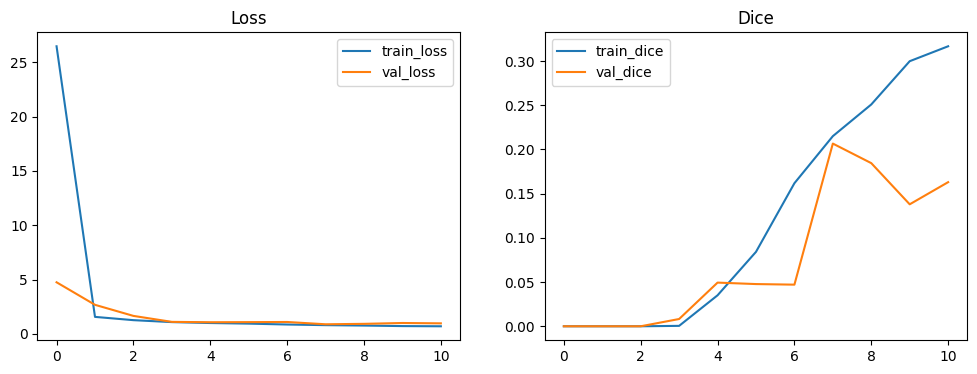

In [34]:
 #---- visualize training curves ----
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend(); plt.title("Loss")
plt.subplot(1,2,2)
plt.plot(history.history['dice_coef'], label='train_dice')
plt.plot(history.history['val_dice_coef'], label='val_dice')
plt.legend(); plt.title("Dice")
plt.show()


In [12]:
model.save('/content/drive/MyDrive/model_backup.h5')


In [15]:
import numpy as np

# Count non-zero pixels in each mask
tumor_present_train = np.sum(Y_train, axis=(1,2,3)) > 0
tumor_present_val   = np.sum(Y_val,   axis=(1,2,3)) > 0

# Keep only slices that contain tumor pixels
X_train_filtered = X_train[tumor_present_train]
Y_train_filtered = Y_train[tumor_present_train]

X_val_filtered = X_val[tumor_present_val]
Y_val_filtered = Y_val[tumor_present_val]

print("Filtered training set:", X_train_filtered.shape, Y_train_filtered.shape)
print("Filtered validation set:", X_val_filtered.shape, Y_val_filtered.shape)


Filtered training set: (245, 128, 128, 4) (245, 128, 128, 1)
Filtered validation set: (65, 128, 128, 4) (65, 128, 128, 1)


In [39]:
X_train_filtered = X_train_filtered.astype(np.float32)
X_val_filtered   = X_val_filtered.astype(np.float32)

# Normalize per-slice (avoid dividing by global max)
X_train_filtered /= np.max(X_train_filtered, axis=(1,2,3), keepdims=True) + 1e-8
X_val_filtered   /= np.max(X_val_filtered, axis=(1,2,3), keepdims=True) + 1e-8



In [40]:
Y_train_filtered = (Y_train_filtered > 0).astype(np.float32)
Y_val_filtered   = (Y_val_filtered > 0).astype(np.float32)



In [44]:
# 3️⃣ Compile Model
model = build_unet(input_shape=(128,128,1))   # ✅ correct for grayscale MRI slices
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coef, 'accuracy']
)




In [45]:
history = model.fit(
    X_train_filtered[:2], Y_train_filtered[:2],
    batch_size=1, epochs=30, verbose=1
)


Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.2434 - dice_coef: 1.6375e-04 - loss: 1.6947
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7238 - dice_coef: 1.6345e-04 - loss: 1.6929
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8846 - dice_coef: 2.0396e-04 - loss: 1.6914
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9681 - dice_coef: 1.6291e-04 - loss: 1.6900 
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9911 - dice_coef: 2.0352e-04 - loss: 1.6885
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9973 - dice_coef: 2.0331e-04 - loss: 1.6871
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9992 - dice_coef: 2.0305e-04 - loss: 1.6856 
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9999 - dice_coef: 2.0279e-04 - loss: 1.6839
Epoch 9/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9999 - dice_coef: 2.0247e-04 - loss: 1.6820
Epoch 10/30
2/2 ━━━━━━━━━━━━━━━━━━

In [47]:
# 3️⃣ Compile Model (fixed for grayscale input)
model = build_unet(input_shape=(128,128,1))
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=bce_dice_loss,
    metrics=[dice_coef, 'accuracy']
)
model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 128, 128,  │        320 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_30[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ conv2d_31[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_32[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ conv2d_33[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_34[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 16, 16,    │          0 │ conv2d_35[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_8[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_36[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16, 16,    │          0 │ conv2d_37[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 32, 32,    │    131,200 │ dropout_2[0][0]   │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_35[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 32, 32,    │    295,040 │ concatenate_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_38[0][0] 

 Total params: 1,925,025 (7.34 MB)

 Trainable params: 1,925,025 (7.34 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
print(X_train_filtered.shape, Y_train_filtered.shape)



(245, 128, 128, 1) (245, 128, 128, 1)


In [59]:
EPOCHS = 15
BATCH_SIZE = 4

history = model.fit(
    X_train_filtered, Y_train_filtered,
    validation_data=(X_val_filtered, Y_val_filtered),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks
)



Epoch 1/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9929 - dice_coef: 0.4478 - loss: 0.5746 - val_accuracy: 0.9870 - val_dice_coef: 0.2346 - val_loss: 0.8399 - learning_rate: 2.5000e-05
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9948 - dice_coef: 0.5260 - loss: 0.4958 - val_accuracy: 0.9865 - val_dice_coef: 0.1926 - val_loss: 0.9027 - learning_rate: 2.5000e-05
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9951 - dice_coef: 0.5244 - loss: 0.4970 - val_accuracy: 0.9864 - val_dice_coef: 0.1382 - val_loss: 0.9783 - learning_rate: 2.5000e-05
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9951 - dice_coef: 0.5313 - loss: 0.4918 - val_accuracy: 0.9863 - val_dice_coef: 0.1451 - val_loss: 0.9718 - learning_rate: 1.2500e-05


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


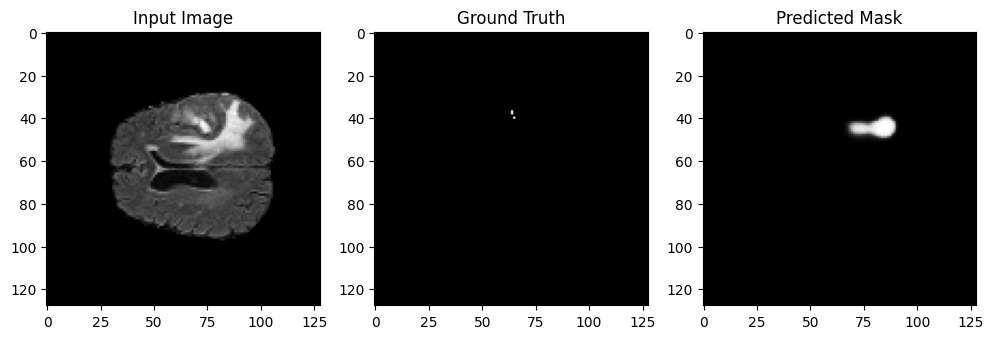

In [64]:
import matplotlib.pyplot as plt

idx = np.random.randint(0, len(X_val_filtered))
sample_img = X_val_filtered[idx]
sample_mask = Y_val_filtered[idx]
pred_mask = model.predict(sample_img[np.newaxis, ...])[0]

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(sample_img[...,0], cmap='gray')
plt.title('Input Image')

plt.subplot(1,3,2)
plt.imshow(sample_mask[...,0], cmap='gray')
plt.title('Ground Truth')

plt.subplot(1,3,3)
plt.imshow(pred_mask[...,0], cmap='gray')
plt.title('Predicted Mask')
plt.show()


In [53]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)


In [54]:
train_gen = datagen.flow(X_train_filtered, Y_train_filtered, batch_size=4)
history = model.fit(
    train_gen,
    validation_data=(X_val_filtered, Y_val_filtered),
    epochs=30,
    callbacks=callbacks
)



Epoch 1/30
 1/62 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.9894 - dice_coef: 0.3635 - loss: 0.7013

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 92ms/step - accuracy: 0.9907 - dice_coef: 0.1808 - loss: 0.8806 - val_accuracy: 0.9854 - val_dice_coef: 0.2109 - val_loss: 0.7539 - learning_rate: 5.0000e-05
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9906 - dice_coef: 0.1828 - loss: 0.8618 - val_accuracy: 0.9842 - val_dice_coef: 0.2676 - val_loss: 0.6680 - learning_rate: 5.0000e-05
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9891 - dice_coef: 0.2183 - loss: 0.8273 - val_accuracy: 0.9839 - val_dice_coef: 0.1670 - val_loss: 0.8124 - learning_rate: 5.0000e-05
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9897 - dice_coef: 0.1992 - loss: 0.8413 - val_accuracy: 0.9841 - val_dice_coef: 0.1827 - val_loss: 0.7884 - learning_rate: 5.0000e-05
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9899 - dice_coef: 0.2022 - loss: 0.8367 - val_accuracy: 0.9844 - val_dice_coef: 0.1299 - val_loss: 0.8690 - learning_rate: 2.5000e-05


In [58]:
# Mount Drive if not already mounted
from google.colab import drive
drive.mount('/content/drive')

# Save to your desired folder in Drive
model.save('/content/drive/MyDrive/models/tumor_segmentation_unet.h5')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


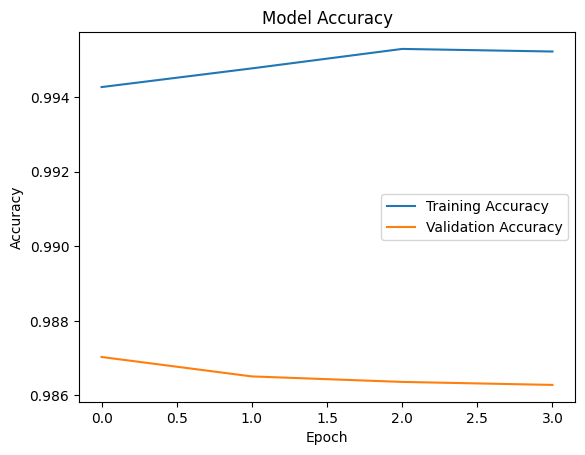

In [65]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()
